Viewing data

# Download the dataset


In [3]:
import numpy as np
from matplotlib import pyplot as plt

In [4]:
# https://drive.google.com/file/d/1CJyTqtCM4kOSQt2X7n2NgWCVEqou8RCB/view?usp=sharing
from google.colab import files
!gdown --id 1CJyTqtCM4kOSQt2X7n2NgWCVEqou8RCB


/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1CJyTqtCM4kOSQt2X7n2NgWCVEqou8RCB
From (redirected): https://drive.google.com/uc?id=1CJyTqtCM4kOSQt2X7n2NgWCVEqou8RCB&confirm=t&uuid=3d82043b-4e5d-431a-988c-6a5c2c2d361a
To: /content/moving_target_dataset.npy
100% 1.52G/1.52G [00:18<00:00, 80.7MB/s]


# Print the classes in the dataset

In [5]:
filename = "moving_target_dataset.npy"
signatures = np.load(filename, allow_pickle=True)

class_names = []
for signature in signatures:
    if not any(signature['class_name'] in s for s in class_names):
        class_names.append(signature['class_name'])

print(class_names)

['vehicle', 'person', 'bicycle', 'uav']


# View the dataset
Shows some samples of the dataset

In [25]:
##%

is_shown = {}
for class_name in class_names:
    is_shown[class_name] = False

(3822, 1008)


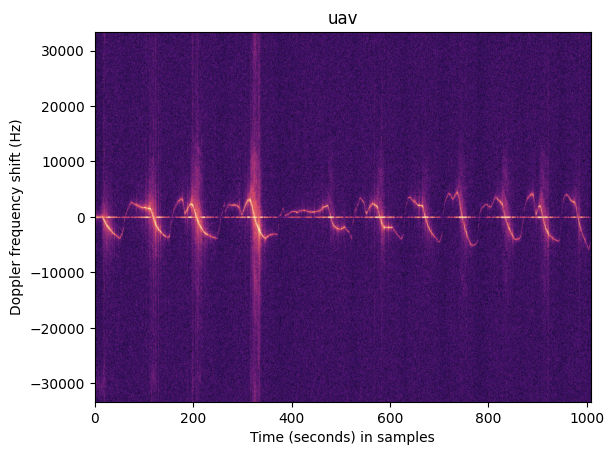

(2381, 1008)


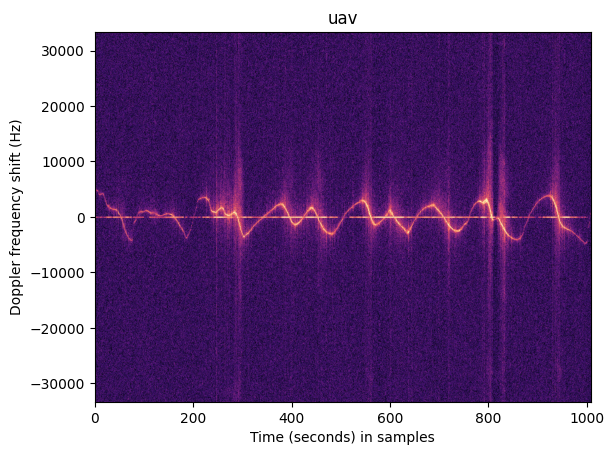

(713, 1008)


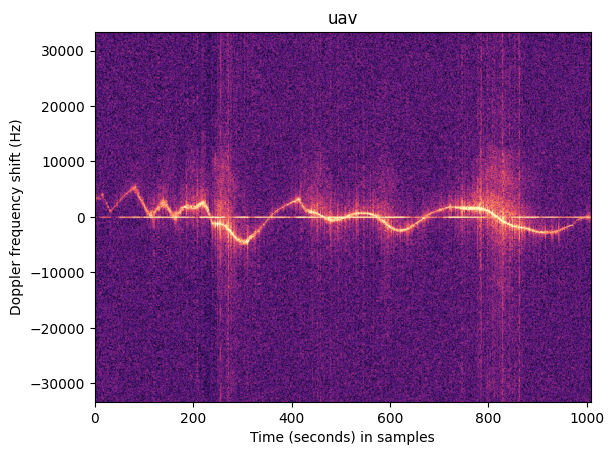

(74, 1008)


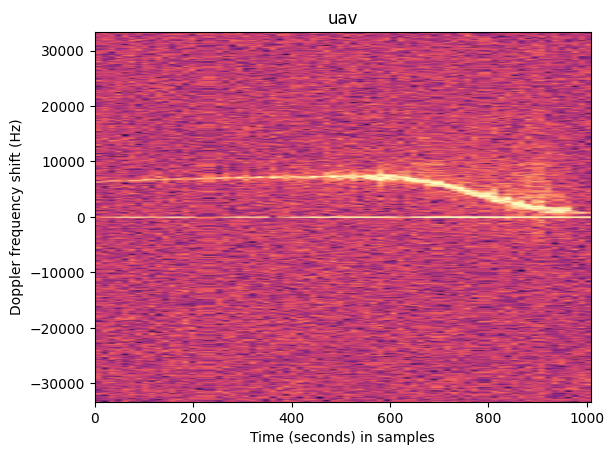

(376, 1008)


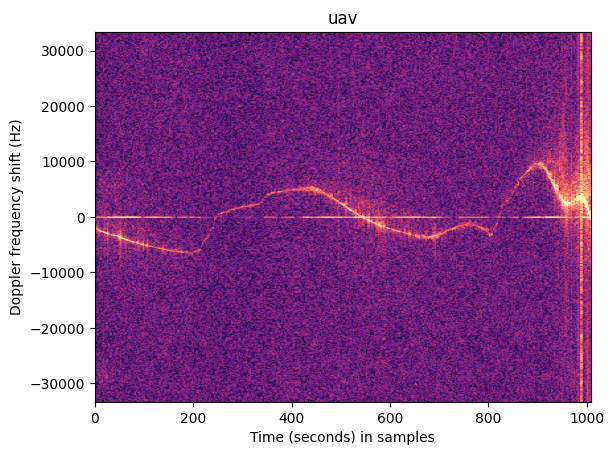

(586, 1008)


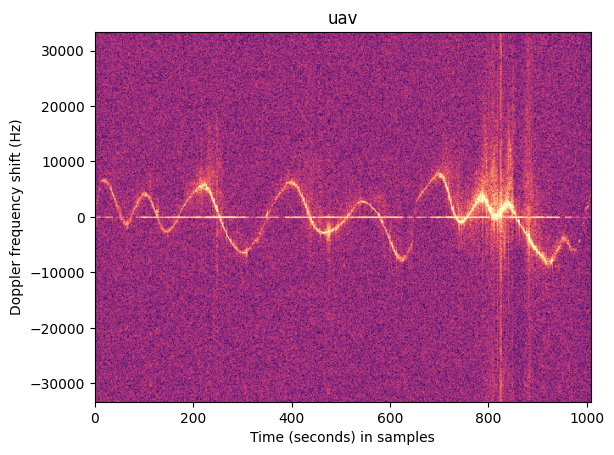

(357, 1008)


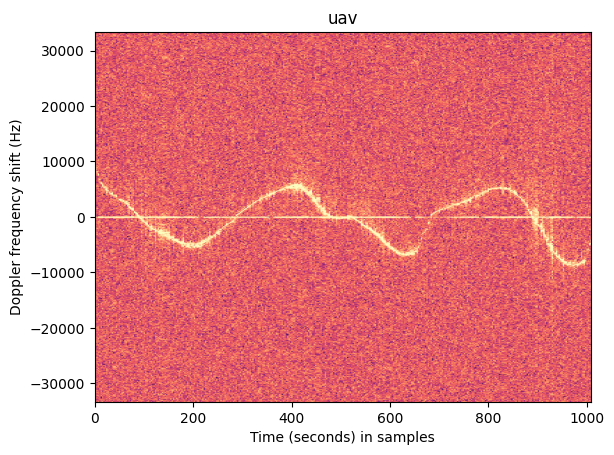

(488, 1008)


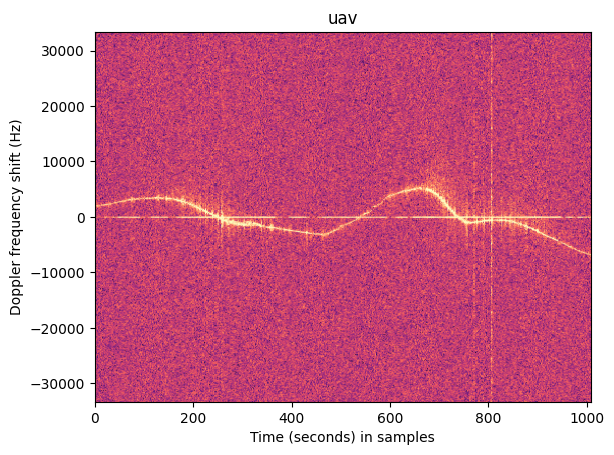

(60, 1008)


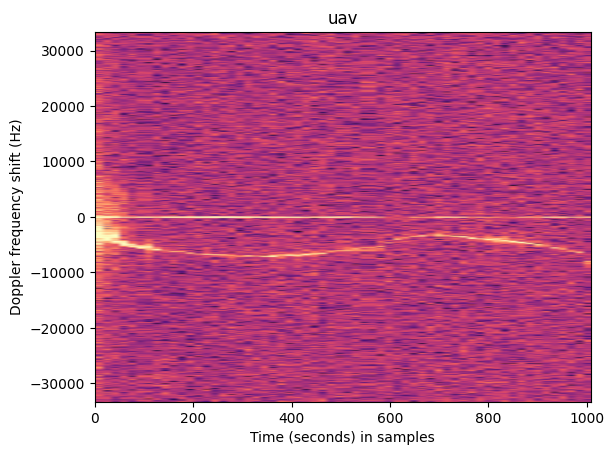

(4933, 1008)


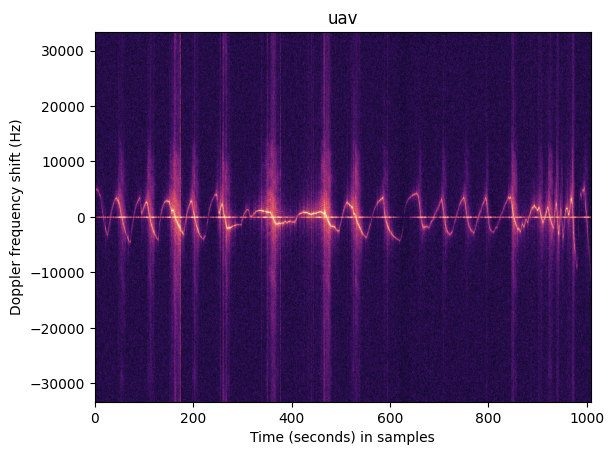

(4651, 1008)


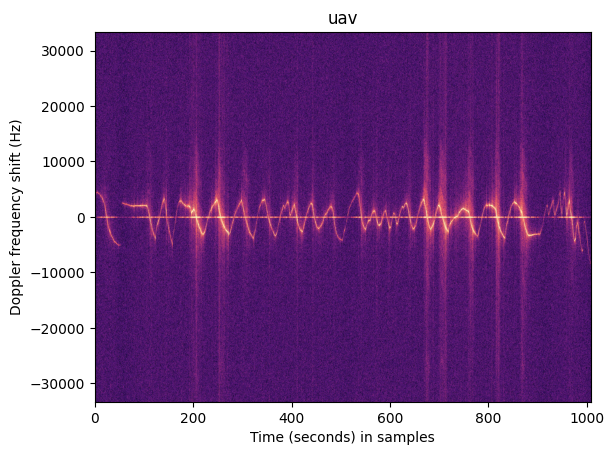

(401, 1008)


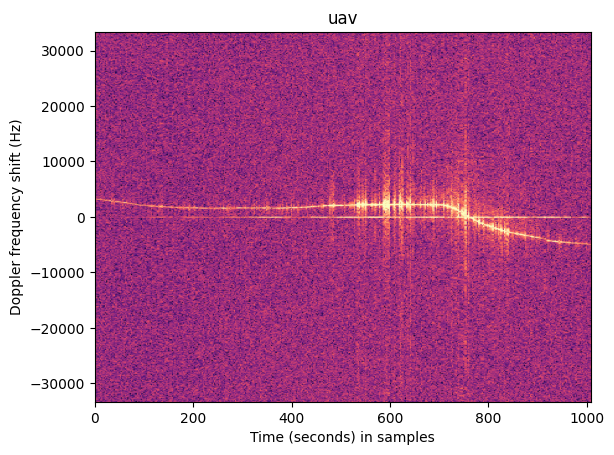

(302, 1008)


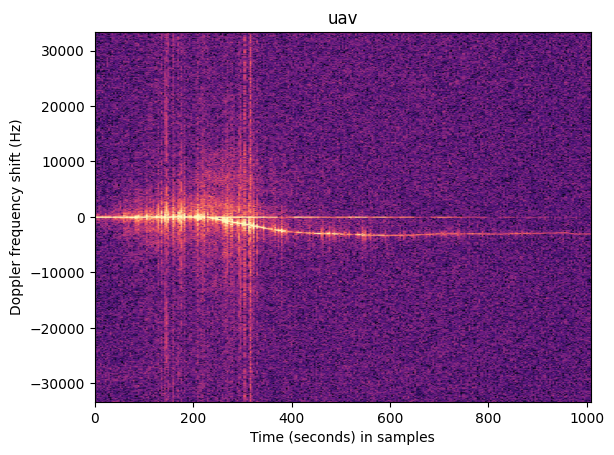

(149, 1008)


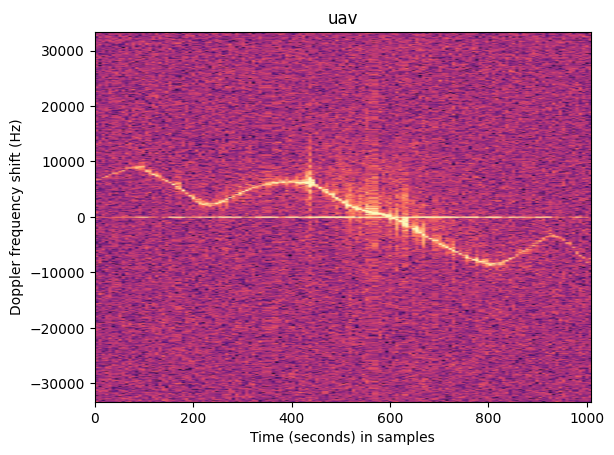

(397, 1008)


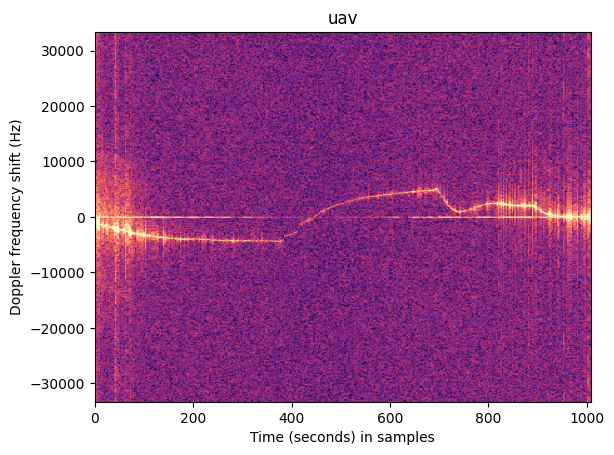

(266, 1008)


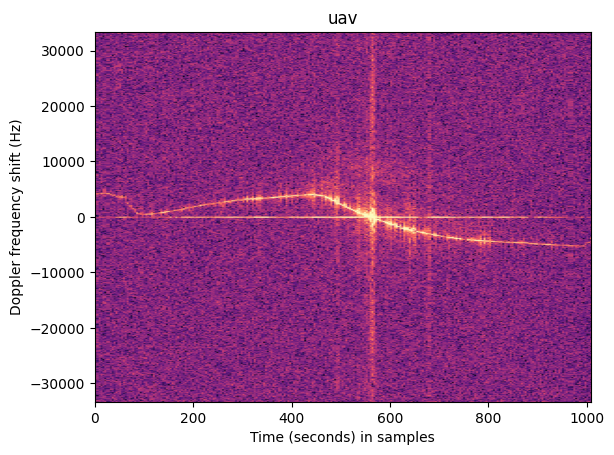

(274, 1008)


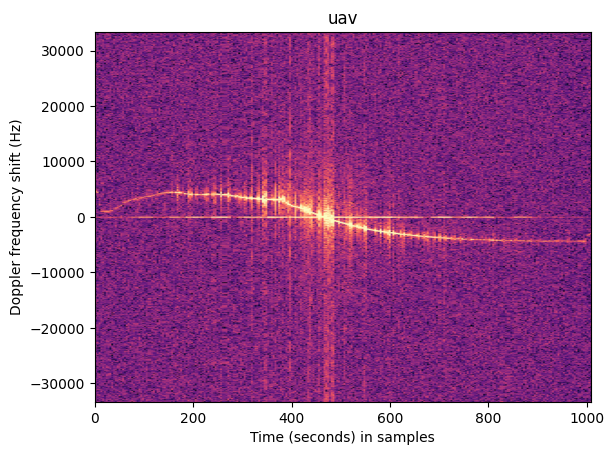

(100, 1008)


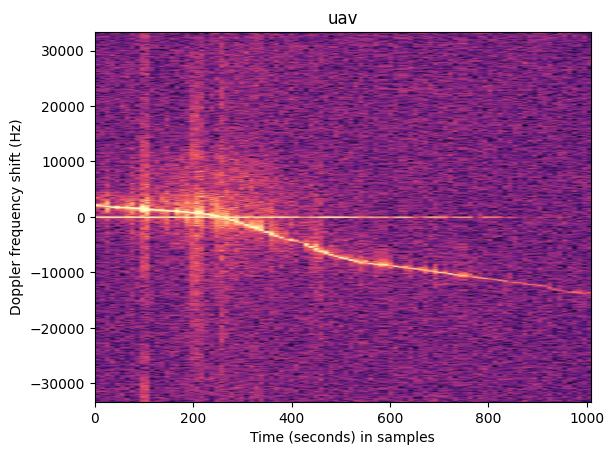

(148, 1008)


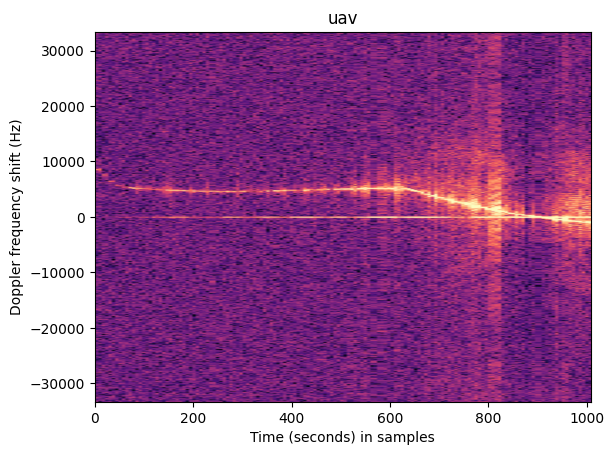

(152, 1008)


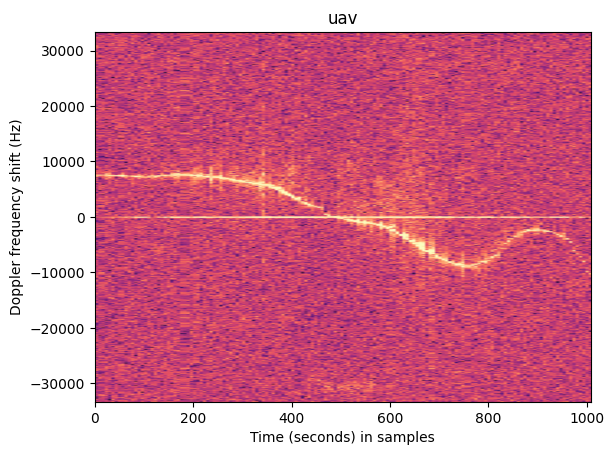

(348, 1008)


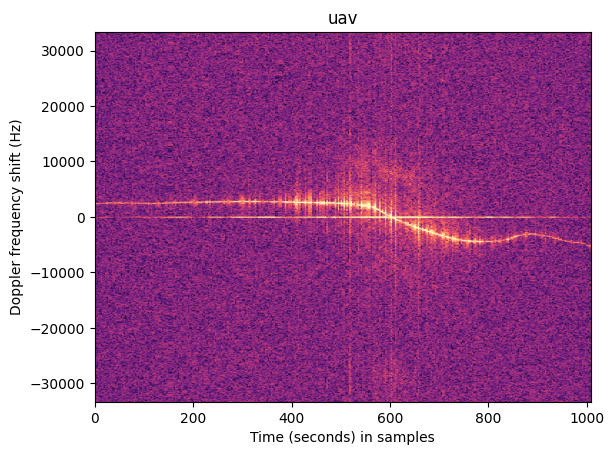

(213, 1008)


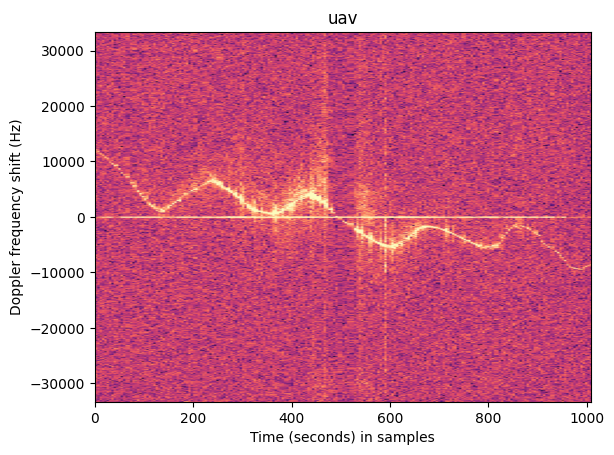

(177, 1008)


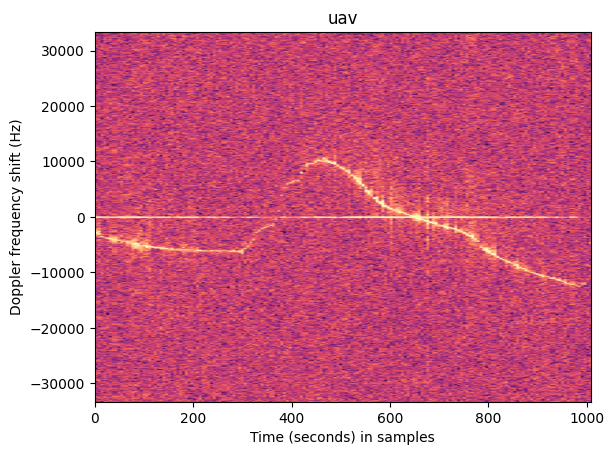

(59, 1008)


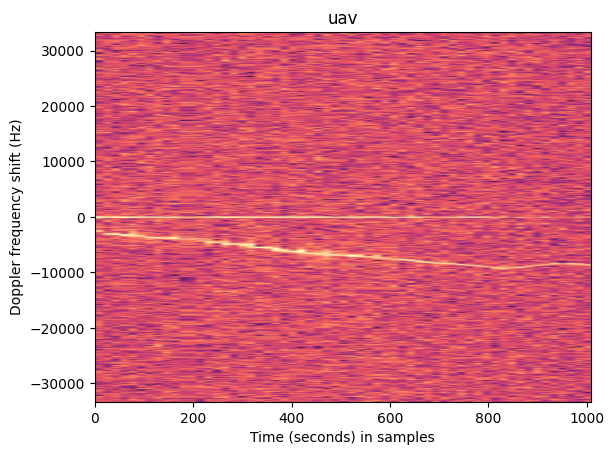

(26, 1008)


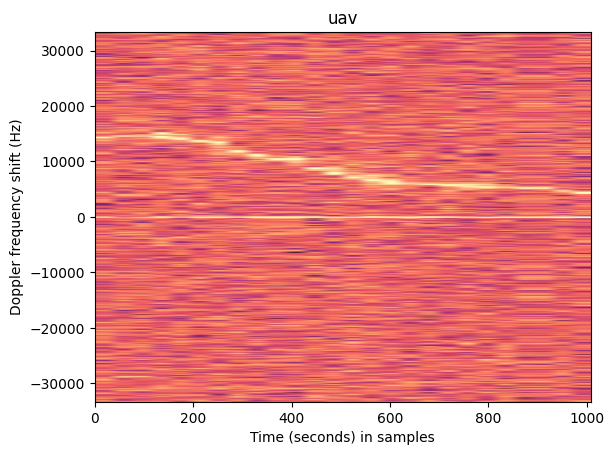

(2680, 1008)


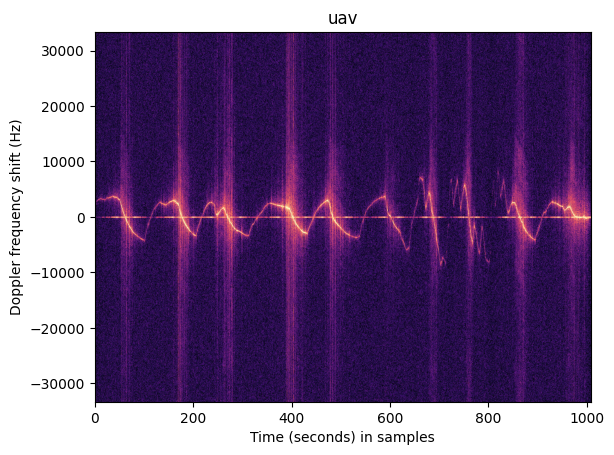

(3702, 1008)


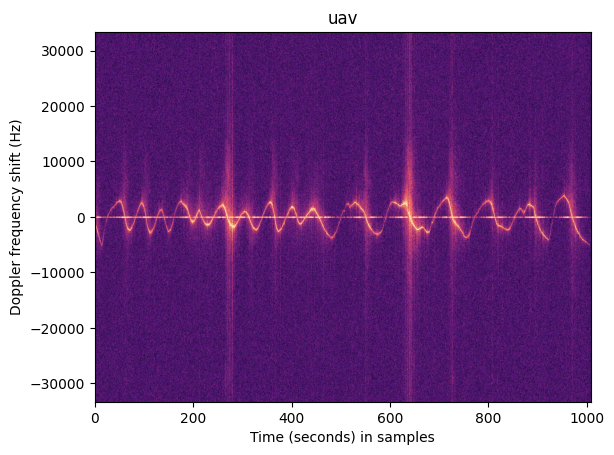

(936, 1008)


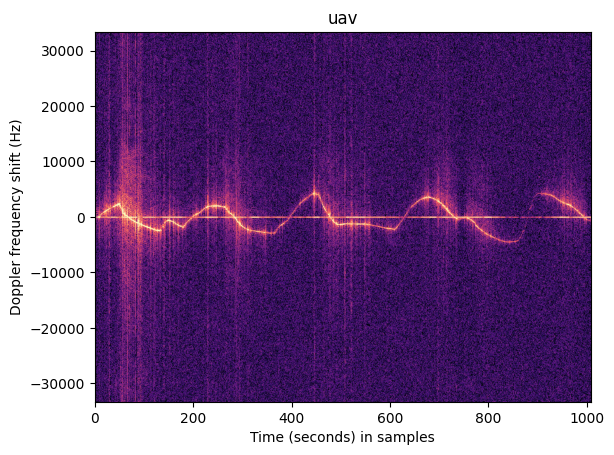

(4078, 1008)


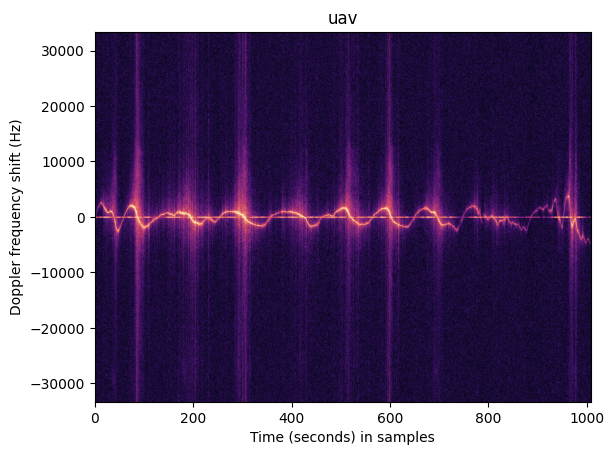

(1597, 1008)


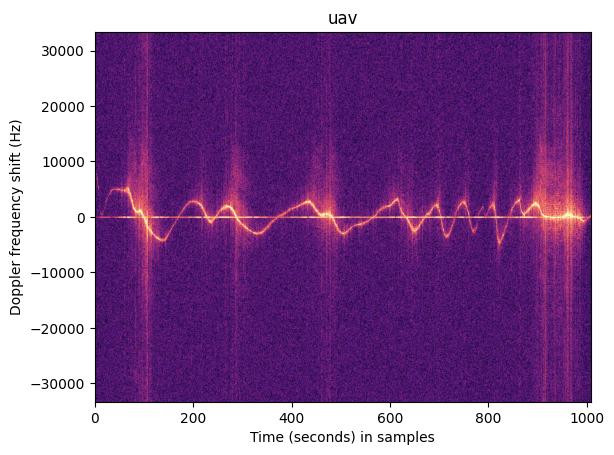

(53, 1008)


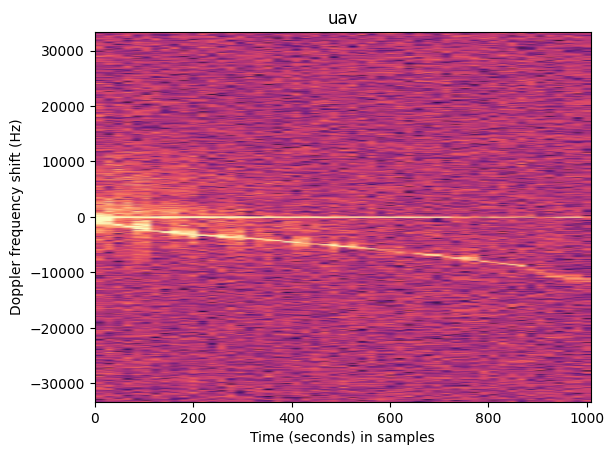

(903, 1008)


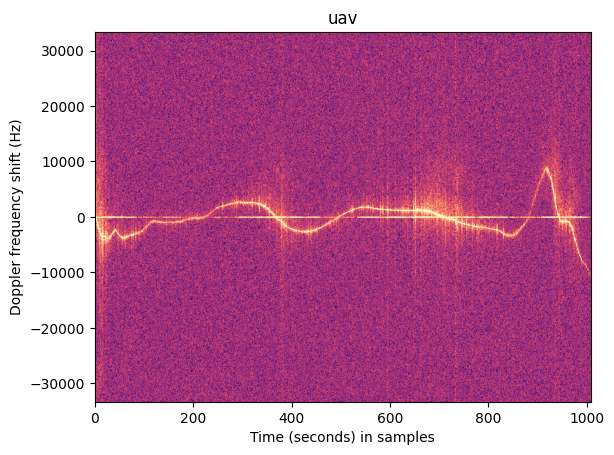

(33, 1008)


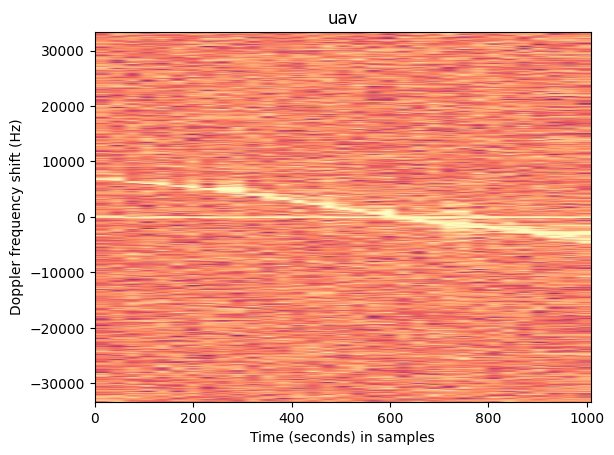

(107, 1008)


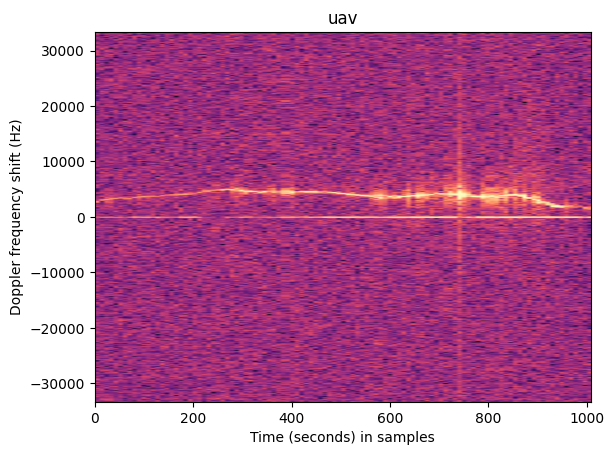

(19, 1008)


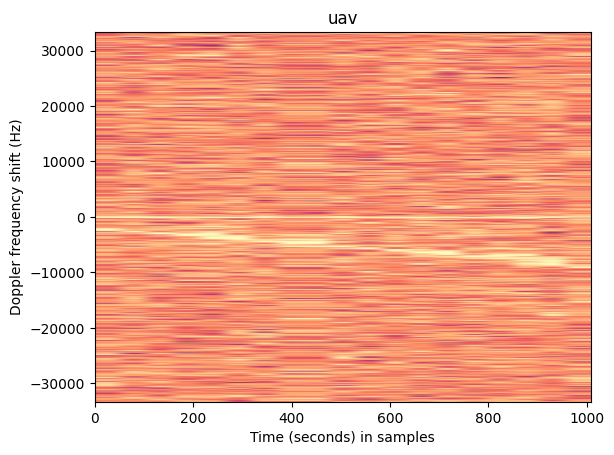

(20, 1008)


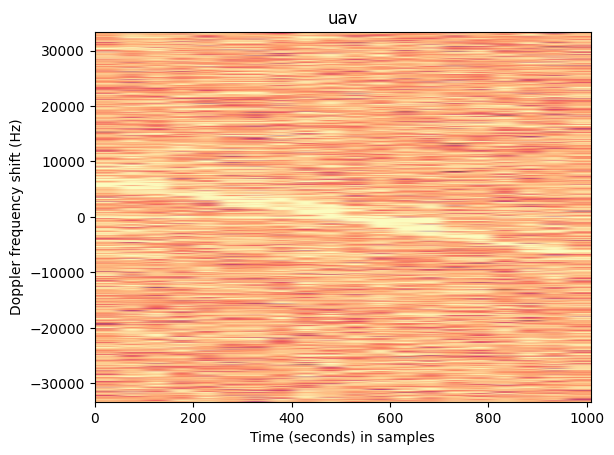

(31, 1008)


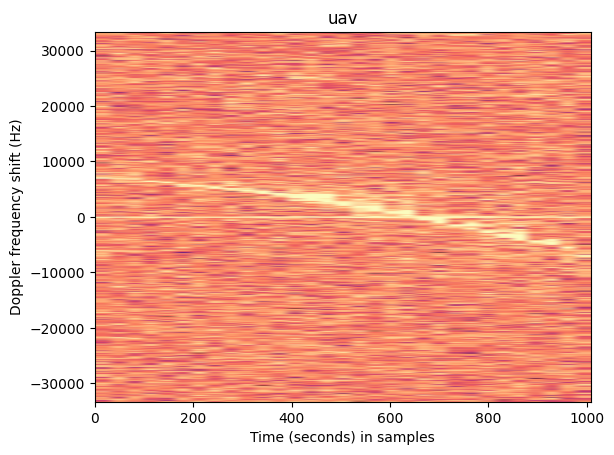

(29, 1008)


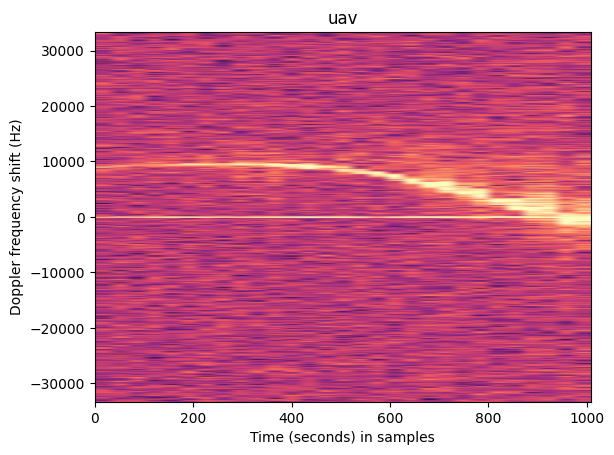

(72, 1008)


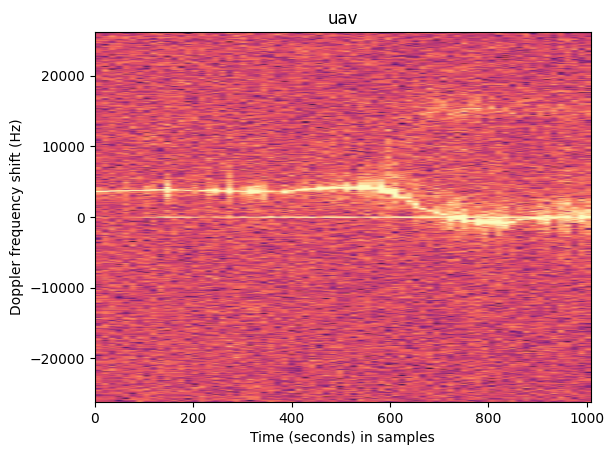

(265, 1008)


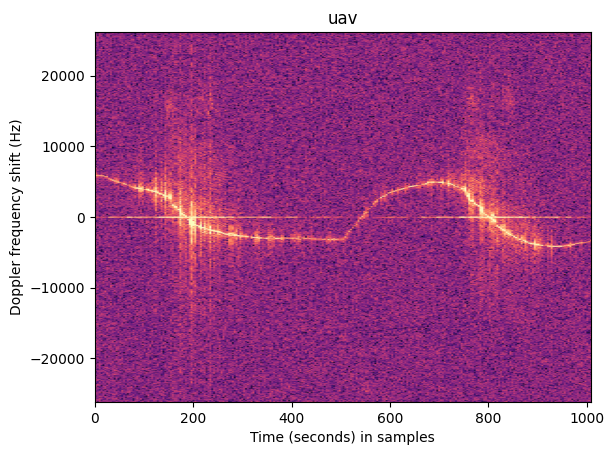

(173, 1008)


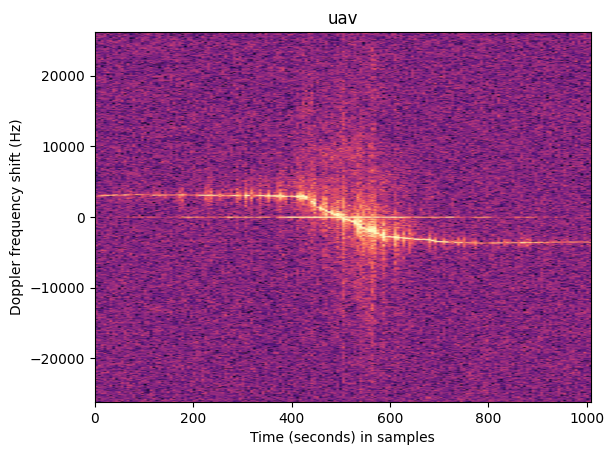

(83, 1008)


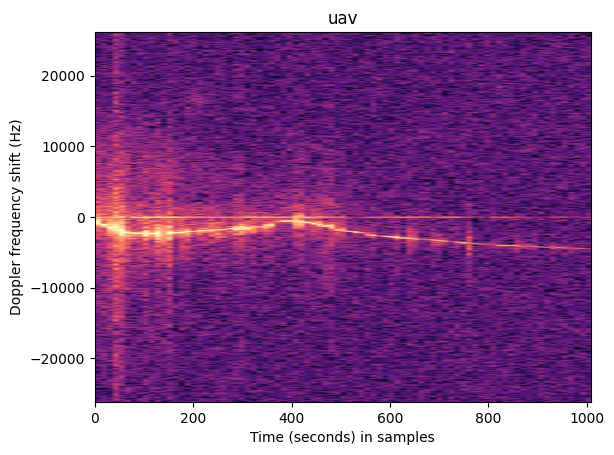

(20, 1008)


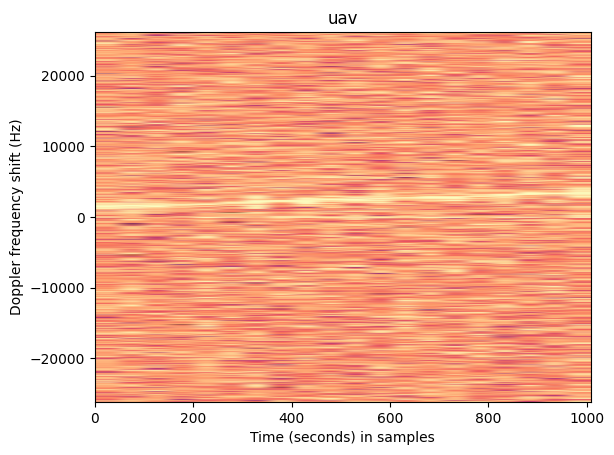

(75, 1008)


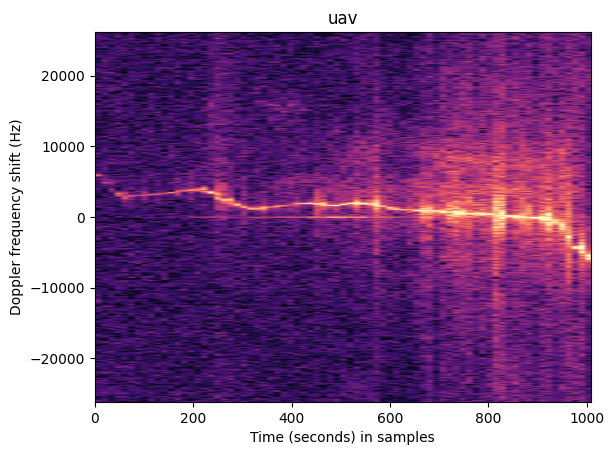

(131, 1008)


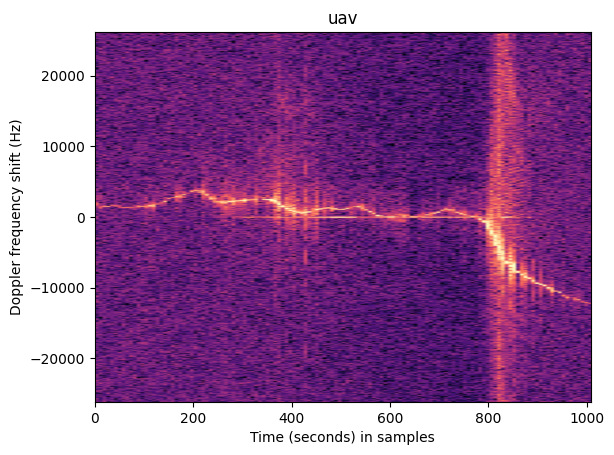

(104, 1008)


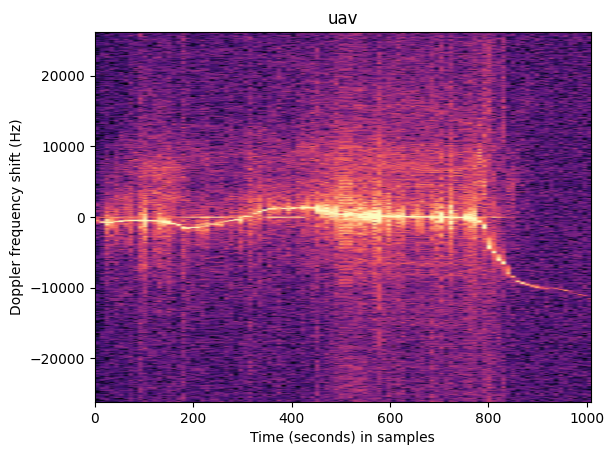

(23, 1008)


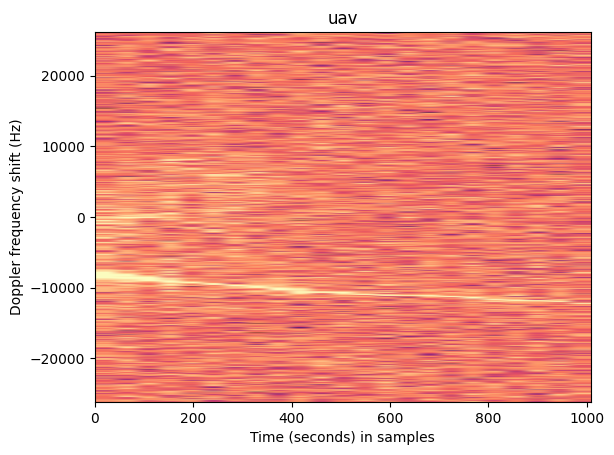

(116, 1008)


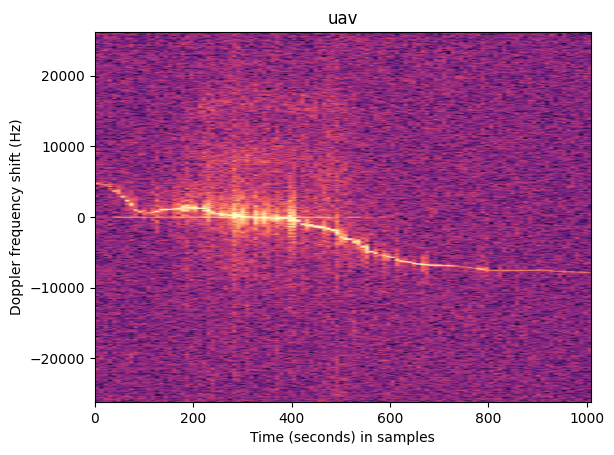

(163, 1008)


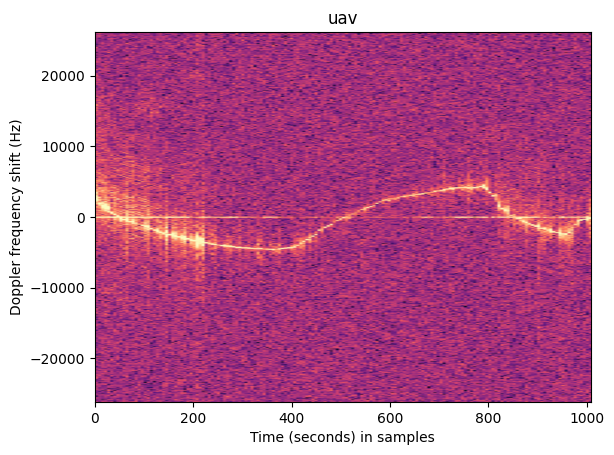

(31, 1008)


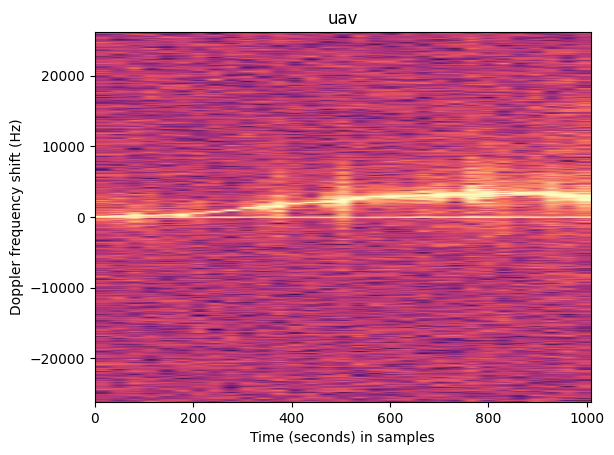

In [28]:

is_shown = {}
for class_name in class_names:
    is_shown[class_name] = False

for signature in signatures:
    if (signature['class_name']=="uav"):
        if(not is_shown[signature['class_name']]):
            is_shown[signature['class_name']] = False
            arr = signature['signature']
            print(arr.shape)
            arr = 20 * np.log10(np.abs(arr)).transpose()
            prf = signature['radar_parameters']['prf']
            plt.imshow(arr, cmap='magma', aspect='auto', vmax=np.max(arr) - 20, vmin=np.max(arr) -70 ,
                          extent=[0, arr.shape[0], -int(prf), int(prf)])
            plt.title(signature['class_name'])
            plt.autoscale()
            # plt.colorbar(axdata)
            plt.xlabel('Time (seconds) in samples')
            plt.ylabel('Doppler frequency shift (Hz)')
            plt.show()

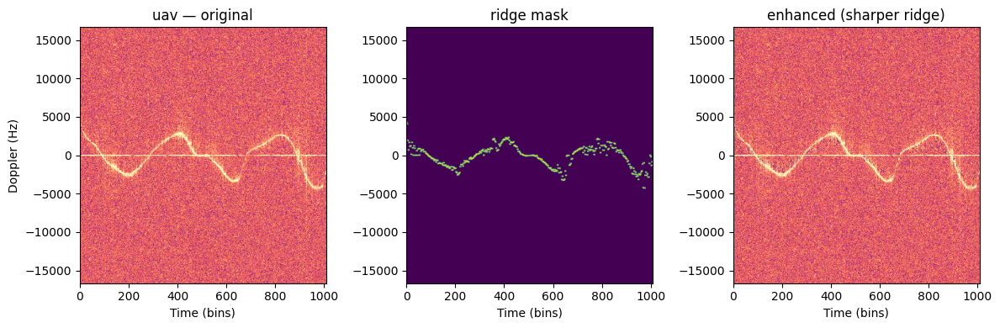

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ---------- ridge-enhance mask (Frangi + ridge-band) ----------
def frangi_ridge_mask(X, sig_f=(0.8,1.3,2.0), sig_t=(8.0,16.0), beta=0.5, c=15.0, eps=1e-8):
    F, T = X.shape
    M = np.zeros_like(X, dtype=np.float32)
    for sf in sig_f:
        for st in sig_t:
            I_ff = gaussian_filter(X, sigma=(sf, st), order=(2,0), mode='nearest')
            I_tt = gaussian_filter(X, sigma=(sf, st), order=(0,2), mode='nearest')
            I_ft = gaussian_filter(X, sigma=(sf, st), order=(1,1), mode='nearest')
            tr = I_ff + I_tt
            det = I_ff*I_tt - I_ft*I_ft
            tmp = np.sqrt(np.maximum(tr*tr/4.0 - det, 0.0))
            l1 = tr/2.0 - tmp
            l2 = tr/2.0 + tmp
            abs1, abs2 = np.abs(l1), np.abs(l2) + eps
            Rb = abs1/abs2
            S  = np.sqrt(l1*l1 + l2*l2)
            V  = np.exp(-(Rb**2)/(2*beta*beta)) * (1.0 - np.exp(-(S**2)/(2*c*c)))
            V[(l2 > 0)] = 0.0  # bright ridges
            M = np.maximum(M, V.astype(np.float32))
    M -= M.min()
    if M.max() > 0: M /= (M.max() + eps)
    return M

def ridge_band_mask(X, alpha=10.0, sigma_f=3.0, add_harmonics=True, delta_search=(10,180)):
    F, T = X.shape
    Xc = X - X.max(axis=0, keepdims=True)
    P  = np.exp(alpha*Xc); P /= (P.sum(axis=0, keepdims=True) + 1e-12)
    freqs = np.arange(F, dtype=np.float32).reshape(-1,1)
    mu = (P * freqs).sum(axis=0)  # (T,)
    M = np.exp(-0.5 * ((freqs - mu.reshape(1,-1))/(sigma_f+1e-6))**2).astype(np.float32)

    if add_harmonics:
        dmin, dmax = delta_search
        delta_bins = np.zeros(T, dtype=np.float32)
        for t in range(T):
            col = X[:, t]
            r = np.correlate(col, col, mode='full')
            r = r[(F-1)+dmin:(F-1)+min(dmax, F-1)+1]
            delta_bins[t] = dmin + np.argmax(r)
        w = 0.35
        for k in (1,2):
            dk = k*delta_bins.reshape(1,-1)
            M += w*np.exp(-0.5 * ((freqs - (mu.reshape(1,-1)+dk))/(sigma_f+1e-6))**2)
            M += w*np.exp(-0.5 * ((freqs - (mu.reshape(1,-1)-dk))/(sigma_f+1e-6))**2)

    M -= M.min()
    if M.max() > 0: M /= (M.max() + 1e-8)
    return M

def ridge_enhance(X01,
                         # mask blend
                         w1=0.9, w2=0.1,
                         # band tracker
                         alpha=102.0, sigma_f=2.0,
                         delta_search_bins=(25,150),  # set from prf/F!
                         add_harmonics=True,
                         # mask shaping
                         gamma=1.2, gate_q=0.85, dilate_t=1,
                         # sharpening
                         gain_small=1.0, blur_small=(1.0, 3.0),
                         gain_big=0.6,  blur_big=(1.5, 5.0)):
    """
    X01: spectrogram normalized to [0,1], shape (F,T)
    Returns: mask in [0,1], enhanced spectrogram in [0,1]
    """
    # 1) masks
    M1 = frangi_ridge_mask(X01, sig_f=(5.8, 3.2, 4.2), sig_t=(8.0, 16.0), beta=2.5, c=15.0)
    M2 = ridge_band_mask(X01, alpha=alpha, sigma_f=sigma_f,
                         add_harmonics=add_harmonics, delta_search=delta_search_bins)
    M  = np.clip(w1*M1 + w2*M2, 0.0, 1.0)

    # 2) gate + contrast (knocks out weak areas)
    if gate_q is not None:
        thr = np.quantile(M, gate_q)
        M = (M - thr) / max(1e-6, (1.0 - thr))
        M[M < 0] = 0
    if gamma != 1.0:
        M = M**gamma

    # optional tiny dilation along time to connect gaps
    if dilate_t > 0:
        from scipy.ndimage import maximum_filter
        M = maximum_filter(M, size=(1, 1 + 2*dilate_t))

    # 3) two-scale unsharp where mask is high
    blur_s  = gaussian_filter(X01, sigma=blur_small)
    blur_b  = gaussian_filter(X01, sigma=blur_big)
    X_enh = X01 + gain_small*(X01 - blur_s)*M + gain_big*(X01 - blur_b)*M
    X_enh = np.clip(X_enh, 0.0, 1.0)
    return M.astype(np.float32), X_enh.astype(np.float32)


# ---------- pick ONE UAV, plot original vs enhanced ----------
def show_one_uav(signatures, class_name="uav"):
    i = 0
    for sig in signatures:
        if sig.get('class_name','').lower() == class_name:
            if(i<6):
             i = i + 1
             continue
            prf = float(sig['radar_parameters']['prf'])  # pulses/s
            arr = sig['signature']                      # complex or magnitude
            X = 20*np.log10(np.abs(arr) + 1e-12).transpose()

            # orient to (F,T): rows=freq, cols=time
            T, F = X.shape


            # contrast like your snippet
            vmin, vmax = X.max() - 70, X.max() - 20
            # normalize to [0,1] for masking
            X01 = (np.clip(X, vmin, vmax) - vmin) / max(vmax - vmin, 1e-6)
            bin_hz = prf / F
            delta_bins = (int(50/bin_hz), int(300/bin_hz))
            mask, X_enh01 = ridge_enhance(
                X01,
                w1=0.1, w2=0.9,
                alpha=100.0, sigma_f=2.0,
                delta_search_bins=delta_bins,
                gamma=1.2, gate_q=0.85,
                gain_small=1.0, blur_small=(1.0,3.0),
                gain_big=0.6,  blur_big=(1.5,5.0)
)



            # back to dB-ish scale (optional)
            X_enh = X_enh01*(vmax - vmin) + vmin

            # axes: time in bins; Doppler in ±PRF/2 (more standard than ±PRF)
            dop_min, dop_max = -prf/2.0, prf/2.0
            extent = [0, T, dop_min, dop_max]

            plt.figure(figsize=(12,4))
            plt.subplot(1,3,1)
            plt.imshow(X, cmap='magma', aspect='auto', vmin=vmin, vmax=vmax,
                       extent=extent)
            plt.title(f'{class_name} — original')
            plt.xlabel('Time (bins)'); plt.ylabel('Doppler (Hz)')

            plt.subplot(1,3,2)
            plt.imshow(mask, cmap='viridis', aspect='auto',
                       extent=extent)
            plt.title('ridge mask'); plt.xlabel('Time (bins)')

            plt.subplot(1,3,3)
            plt.imshow(X_enh, cmap='magma', aspect='auto',
                       vmin=vmin, vmax=vmax, extent=extent)
            plt.title('enhanced (sharper ridge)')
            plt.xlabel('Time (bins)')

            plt.tight_layout(); plt.show()
            break  # only the first UAV

# ---- run it
show_one_uav(signatures, class_name="uav")




The files in the dataset are of long tracks of each subject, to use them for

*   List item
*   List item

machine learning tests,
it is important that we split the the data on the track-basis an not only spectra.
We therefore perform the spliting at this point.

In [11]:


from sklearn.model_selection import train_test_split
from sklearn import preprocessing

all_indices = list(range(len(signatures)))
train_indices, test_indices = train_test_split(all_indices, test_size=0.2, random_state=42)

le = preprocessing.LabelEncoder()
le.fit_transform(class_names)

# for ind in train_indices:
train_signatures = [signatures[i] for i in train_indices]
test_signatures = [signatures[i] for i in test_indices]

#Count the Number of samples:
n_samples_train = 0
n_samples_test = 0
for signature in train_signatures:
    n_samples_train += len(signature['ts'])

for signature in test_signatures:
    n_samples_test += len(signature['ts'])


print("Train dataset size: " +str(n_samples_train))
print("Test dataset size: " +str(n_samples_test))


Train dataset size: 151455
Test dataset size: 35937


These two datasets now contain everything you need to do classification research.
You simply have to slice the spectrograms into convenient sizes and start the challenge.
Each spectra contains 1008 Doppler bins and concatinating 10 spectra corresponds to half a second observation time.
